# 05 Model evaluation
Reads `results/metrics.json` from `python setup_project.py`. No number here is typed in by hand.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
pd.set_option("display.max_colwidth", 110)
import json
R = json.loads((ROOT / 'results/metrics.json').read_text())
print(R['generated_at'], R['machine'])
{k: v['status'] for k, v in R['models'].items()}

2026-11-17T12:58:02 Linux x86_64, Python 3.12.3


{'tfidf': 'ok', 'sbert': 'not_run'}

In [2]:
ok = {k: v for k, v in R['models'].items() if v['status'] == 'ok'}
pd.DataFrame({v['display_name']: {**{k: v['test'][k] for k in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']},
    'threshold': v['threshold'], 'recall@5': v['retrieval']['recall@5'], 'ms per query': v['speed_ms']['mean']}
    for v in ok.values()}).T.round(3)

,accuracy,precision,recall,f1,roc_auc,threshold,recall@5,ms per query
TF-IDF,0.702,0.653,0.864,0.744,0.794,0.038,0.244,1.919


In [3]:
pd.DataFrame({v['display_name']: v['accuracy_by_pair_type'] for v in ok.values()}).round(3)

,TF-IDF
duplicate_same_issue,0.864
easy_random,0.867
hard_same_locality_diff_category,0.327
hard_same_locality_same_category,0.332
hard_same_subcategory_diff_locality,0.520
medium_same_category_diff_locality,0.707


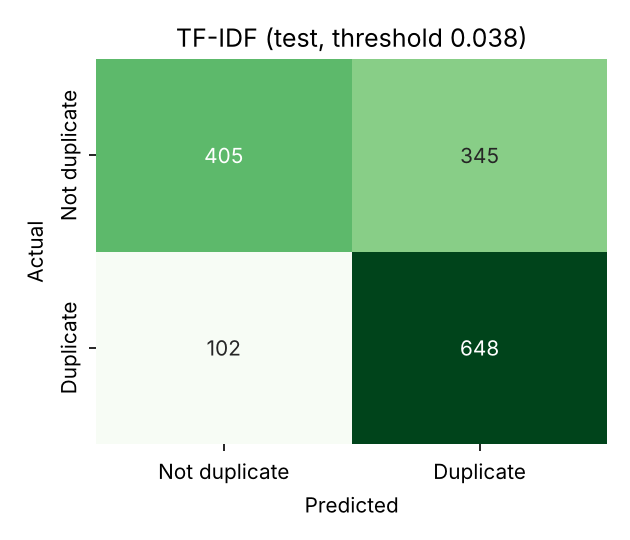

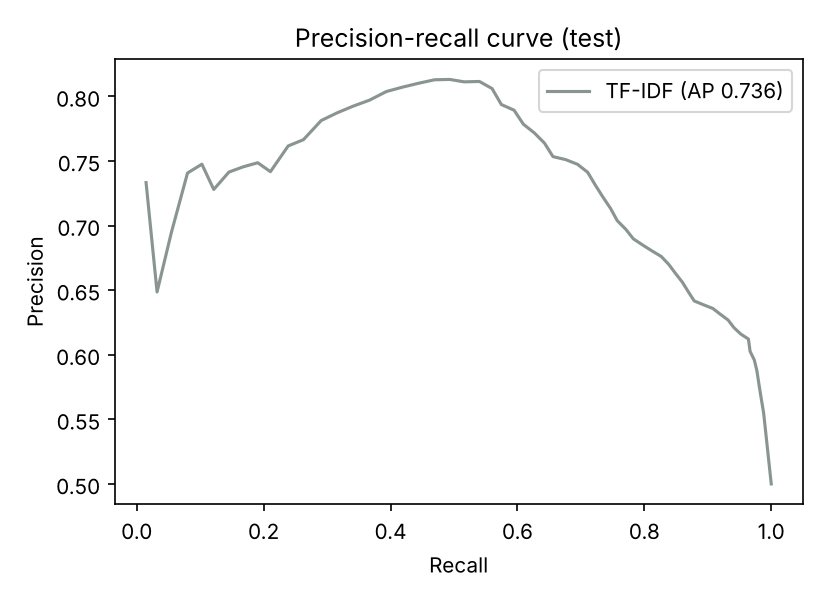

In [4]:
from IPython.display import Image, display
for f in sorted((ROOT / 'results/figures').glob('*.png')):
    display(Image(filename=str(f)))